# 🌊 Shakespeare Diffusion LLM — Masked Discrete Diffusion Trainer

A trainable **Masked Diffusion Language Model (MDLM)** implemented in PyTorch.  
Same Shakespeare dataset as the GPT notebook — directly comparable.

### How it differs from your GPT
| Property | GPT (autoregressive) | This: Masked Diffusion |
|---|---|---|
| Generation order | Left → right, one token at a time | **All positions at once**, iterative unmasking |
| Context | Causal (can't see future) | **Bidirectional** (sees full sequence) |
| Noise process | N/A | Random token masking (0% → 100%) |
| Denoising | N/A | Predict masked tokens, repeat T steps |
| Training objective | Cross-entropy on next token | Cross-entropy on **masked** tokens only |
| Parallelism | Sequential | **Fully parallel** per diffusion step |

### The Diffusion Process (Discrete / Masked)
```
Forward (add noise):   x₀ → x₁ → x₂ → ... → xₜ
                     clean  10%  30%  ...  100% masked

Reverse (denoise):    xₜ → ... → x₁ → x₀
                     noisy  ...  90%  fully recovered
```
The model learns `p(x₀ | xₜ)` — given a partially masked sequence, predict all original tokens.

---

## 1. Install Dependencies

In [1]:
# Run once — comment out after first run
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121 -q
# !pip install matplotlib tqdm numpy -q
print('✅ Dependencies ready')

✅ Dependencies ready


## 2. Imports & Device

In [2]:
import os, math, time, random, platform
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ── Device ───────────────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32       = True
    print(f'✅ GPU : {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('⚠️  CPU only — training will be slow')

torch.manual_seed(1337)
np.random.seed(1337)
random.seed(1337)
print(f'   Platform : {platform.system()}')

✅ GPU : NVIDIA GeForce RTX 4060 Laptop GPU
   VRAM: 8.6 GB
   Platform : Windows


## 3. Hyperparameters

In [3]:
@dataclass
class Config:
    # ── Tokenizer (set after vocab build) ────────────────────────────────
    vocab_size : int   = 65     # char-level shakespeare
    mask_token : int   = 0      # reserved index; shifted after vocab build

    # ── Model ────────────────────────────────────────────────────────────
    block_size : int   = 128    # sequence length  (shorter than GPT → faster)
    n_layer    : int   = 6      # transformer encoder blocks
    n_head     : int   = 6      # attention heads
    n_embd     : int   = 384    # embedding dim  (~10 M params, same as GPT nb)
    dropout    : float = 0.1

    # ── Diffusion ─────────────────────────────────────────────────────────
    # T diffusion timesteps: at step t, each token is independently masked
    # with probability t/T  (linear noise schedule)
    T          : int   = 100    # total diffusion steps
    loss_type  : str   = "simple"  # "simple" (stable) or "elbo" (reweighted)
    # Inference: how many denoising passes to run
    sample_steps: int  = 50     # more steps = better quality

    # ── Training ─────────────────────────────────────────────────────────
    batch_size    : int   = 64
    max_iters     : int   = 8000
    eval_interval : int   = 250
    eval_iters    : int   = 50

    # ── Optimiser ────────────────────────────────────────────────────────
    learning_rate : float = 3e-4
    min_lr        : float = 3e-5
    warmup_iters  : int   = 500
    weight_decay  : float = 0.1
    grad_clip     : float = 1.0

    # ── AMP / IO ──────────────────────────────────────────────────────────
    use_amp   : bool = True
    out_dir   : str  = 'checkpoints_diffusion'
    data_file : str  = 'shakespeare.txt'

cfg = Config()
Path(cfg.out_dir).mkdir(exist_ok=True)
print('Config ready')
print(f'  Sequence length : {cfg.block_size}')
print(f'  Diffusion steps : {cfg.T}  (sampling with {cfg.sample_steps} steps)')

Config ready
  Sequence length : 128
  Diffusion steps : 100  (sampling with 50 steps)


## 4. Data

In [4]:
import urllib.request

URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
if not Path(cfg.data_file).exists():
    print('Downloading …')
    urllib.request.urlretrieve(URL, cfg.data_file)

text = Path(cfg.data_file).read_text(encoding='utf-8')
print(f'✅ {len(text):,} characters loaded')
print(f'   Sample: {text[:80]!r}')

✅ 1,115,394 characters loaded
   Sample: 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.'


## 5. Tokenizer

Character-level — same as the GPT notebook.  
We reserve **index 0** as the `[MASK]` token and shift all real characters up by 1.

In [5]:
# ── Build vocab ───────────────────────────────────────────────────────────────
chars = sorted(set(text))

# Shift real chars by +1 so index 0 is free for [MASK]
MASK_ID = 0
stoi    = {ch: i + 1 for i, ch in enumerate(chars)}   # char → id (1-based)
itos    = {i + 1: ch for i, ch in enumerate(chars)}   # id → char
itos[MASK_ID] = '[M]'

encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos.get(i, '?') for i in l)

cfg.vocab_size = len(chars) + 1   # +1 for MASK
cfg.mask_token = MASK_ID

print(f'Vocab size (incl. [MASK]): {cfg.vocab_size}')
print(f'MASK token id            : {MASK_ID}')

# ── Train / val split ─────────────────────────────────────────────────────────
data       = torch.tensor(encode(text), dtype=torch.long)
n          = int(0.9 * len(data))
train_data = data[:n]
val_data   = data[n:]
print(f'Train tokens: {len(train_data):,}   Val tokens: {len(val_data):,}')

Vocab size (incl. [MASK]): 66
MASK token id            : 0
Train tokens: 1,003,854   Val tokens: 111,540


## 6. Dataset & Noise Schedule

The dataset returns a raw clean sequence `x₀`.  
The **noise schedule** defines `β(t)` — the masking probability at timestep `t`.

We use a **linear schedule**: `β(t) = t / T`, so at `t=0` nothing is masked, at `t=T` everything is masked.

Platform     : Windows  |  num_workers=0
Train batches: 15,683  |  Val batches: 1,740


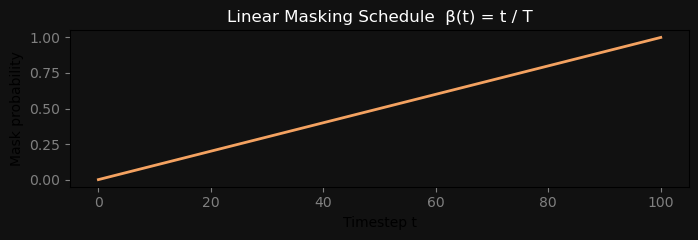

In [6]:
class ShakespeareDataset(Dataset):
    def __init__(self, data: torch.Tensor, block_size: int):
        self.data       = data
        self.block_size = block_size

    def __len__(self):
        return len(self.data) - self.block_size

    def __getitem__(self, idx):
        return self.data[idx : idx + self.block_size]


class MaskingNoise:
    """
    Implements the forward diffusion process for discrete masked diffusion.

    Given a clean sequence x0 and a timestep t, returns a noisy sequence xt
    where each token is independently replaced with MASK_ID with probability
    mask_prob(t) = t / T  (linear schedule).
    """
    def __init__(self, T: int, mask_id: int):
        self.T       = T
        self.mask_id = mask_id

    def mask_prob(self, t: torch.Tensor) -> torch.Tensor:
        """t: (B,) integer timesteps  →  masking probability (B,)"""
        return t.float() / self.T

    def forward(self, x0: torch.Tensor, t: torch.Tensor):
        """
        x0  : (B, L)  clean token ids
        t   : (B,)    integer timesteps in [1, T]
        Returns:
            xt   : (B, L) noisy (partially masked) sequence
            mask : (B, L) bool — True where token was masked
        """
        B, L    = x0.shape
        probs   = self.mask_prob(t)          # (B,)
        # Expand to (B, L) for per-token Bernoulli sampling
        probs   = probs.unsqueeze(1).expand(B, L)
        mask    = torch.bernoulli(probs).bool().to(x0.device)
        xt      = x0.clone()
        xt[mask] = self.mask_id
        return xt, mask


# ── DataLoaders ───────────────────────────────────────────────────────────────
NUM_WORKERS = 0 if platform.system() == 'Windows' else 2
PIN_MEM     = device.type == 'cuda'

train_ds = ShakespeareDataset(train_data, cfg.block_size)
val_ds   = ShakespeareDataset(val_data,   cfg.block_size)

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size,
                          shuffle=True,  pin_memory=PIN_MEM,
                          num_workers=NUM_WORKERS, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=cfg.batch_size,
                          shuffle=False, pin_memory=PIN_MEM,
                          num_workers=NUM_WORKERS, drop_last=True)

noise = MaskingNoise(T=cfg.T, mask_id=cfg.mask_token)

print(f'Platform     : {platform.system()}  |  num_workers={NUM_WORKERS}')
print(f'Train batches: {len(train_loader):,}  |  Val batches: {len(val_loader):,}')

# Quick sanity check — visualise the noise schedule
ts    = torch.arange(0, cfg.T + 1)
probs = ts.float() / cfg.T
plt.figure(figsize=(7, 2.5))
plt.plot(ts.numpy(), probs.numpy(), color='#f4a261', lw=2)
plt.title('Linear Masking Schedule  β(t) = t / T', color='white')
plt.xlabel('Timestep t'); plt.ylabel('Mask probability')
plt.gca().set_facecolor('#111'); plt.gcf().set_facecolor('#111')
plt.tick_params(colors='grey'); plt.tight_layout(); plt.show()

## 7. Model — Bidirectional Transformer Denoiser

Unlike the GPT notebook (causal / decoder-only), this uses a **full bidirectional encoder**:  
every position can attend to every other position.  This is essential because to denoise a
masked token you need context from *both sides*.

The model also receives a **timestep embedding** so it knows how noisy the input is.

In [7]:
# ── Sinusoidal timestep embedding ─────────────────────────────────────────────
class TimestepEmbedding(nn.Module):
    """Maps scalar timestep t → dense vector of dim `dim`."""
    def __init__(self, dim: int):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 2),
            nn.SiLU(),
            nn.Linear(dim * 2, dim),
        )
        self.dim = dim

    def sinusoidal(self, t: torch.Tensor) -> torch.Tensor:
        """t: (B,) int  →  (B, dim) sinusoidal features"""
        half  = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(half, device=t.device) / (half - 1)
        )                                          # (half,)
        args  = t.float().unsqueeze(1) * freqs     # (B, half)
        emb   = torch.cat([args.sin(), args.cos()], dim=-1)  # (B, dim)
        return emb

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        return self.mlp(self.sinusoidal(t))        # (B, dim)


# ── Encoder block (bidirectional — NO causal mask) ────────────────────────────
class EncoderBlock(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.ln1  = nn.LayerNorm(cfg.n_embd)
        self.attn = nn.MultiheadAttention(
            cfg.n_embd, cfg.n_head,
            dropout=cfg.dropout, batch_first=True, bias=False
        )
        self.ln2  = nn.LayerNorm(cfg.n_embd)
        self.mlp  = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=False),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=False),
            nn.Dropout(cfg.dropout),
        )
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        # Bidirectional self-attention (no attn_mask → full attention)
        h, _ = self.attn(self.ln1(x), self.ln1(x), self.ln1(x), need_weights=False)
        x    = x + self.drop(h)
        x    = x + self.mlp(self.ln2(x))
        return x


# ── Full Diffusion Denoiser ───────────────────────────────────────────────────
class DiffusionDenoiser(nn.Module):
    """
    Bidirectional transformer that predicts the original (unmasked) token
    at every position given a partially masked sequence xt and timestep t.

    Input : xt  (B, L)  — noisy token ids
            t   (B,)    — diffusion timestep
    Output: logits (B, L, vocab_size)  — predicted logits for every position
    """
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg

        self.tok_emb  = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb  = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.t_emb    = TimestepEmbedding(cfg.n_embd)
        self.drop     = nn.Dropout(cfg.dropout)

        self.blocks   = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg.n_layer)])
        self.ln_f     = nn.LayerNorm(cfg.n_embd)
        self.lm_head  = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)

        # Weight tying
        self.tok_emb.weight = self.lm_head.weight

        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, xt: torch.Tensor, t: torch.Tensor):
        B, L = xt.shape
        pos  = torch.arange(L, device=xt.device)          # (L,)

        # Token + position embeddings
        x = self.drop(self.tok_emb(xt) + self.pos_emb(pos))  # (B, L, D)

        # Inject timestep: broadcast (B, D) → add to every position
        t_vec = self.t_emb(t).unsqueeze(1)                 # (B, 1, D)
        x     = x + t_vec

        for block in self.blocks:
            x = block(x)

        x      = self.ln_f(x)
        logits = self.lm_head(x)                           # (B, L, V)
        return logits

    def num_params(self):
        return sum(p.numel() for p in self.parameters())


# ── Instantiate ───────────────────────────────────────────────────────────────
model = DiffusionDenoiser(cfg).to(device)
print(f'✅ DiffusionDenoiser | {model.num_params()/1e6:.2f} M parameters')
print(f'   Attention type : Bidirectional (full, no causal mask)')
print(f'   Timestep cond  : Sinusoidal embedding → MLP → added to all positions')

✅ DiffusionDenoiser | 11.29 M parameters
   Attention type : Bidirectional (full, no causal mask)
   Timestep cond  : Sinusoidal embedding → MLP → added to all positions


## 8. Training Objective

**MDLM Loss** — cross-entropy over masked positions only, weighted by `1 / mask_prob(t)`.

The weighting is the ELBO (Evidence Lower BOund) reweighting from the MDLM paper:
higher-noise timesteps (more masked tokens) get down-weighted so the model doesn't
over-focus on easy high-noise predictions.

```
L = E_t [ 1/β(t) · CE(f(xt, t), x0) ]    over masked positions only
```

In [8]:
def diffusion_loss(model, x0, noise_schedule, use_amp=True):
    """
    Masked-diffusion training loss.

    loss_type="simple"  → plain mean CE over masked tokens (stable, recommended).
    loss_type="elbo"    → ELBO-reweighted by 1/β(t) (theoretically tighter but
                          numerically explosive at low t — needs careful clamping).
    """
    B, L = x0.shape

    # Sample timestep: t ~ Uniform[1, T]
    t = torch.randint(1, noise_schedule.T + 1, (B,), device=x0.device)

    # Forward diffusion: corrupt x0 → xt
    xt, mask = noise_schedule.forward(x0, t)

    if not mask.any():
        return torch.tensor(0.0, device=x0.device, requires_grad=True)

    # Predict x0 from (xt, t)
    with autocast("cuda", enabled=use_amp):
        logits = model(xt, t)                   # (B, L, V)

    logits_flat = logits.view(B * L, -1)        # (B*L, V)
    targets     = x0.view(B * L)               # (B*L,)
    mask_flat   = mask.view(B * L)             # (B*L,) bool

    ce = F.cross_entropy(logits_flat, targets, reduction="none")  # (B*L,)
    ce = ce * mask_flat.float()                 # zero out unmasked positions

    if cfg.loss_type == "elbo":
        # ELBO reweighting — clamp to avoid explosion at tiny β(t)
        mask_prob = noise_schedule.mask_prob(t).clamp(min=0.05)   # (B,)
        weight    = (1.0 / mask_prob).clamp(max=20.0)             # (B,) capped
        weight    = weight.unsqueeze(1).expand(B, L).reshape(B * L)
        loss = (ce * weight).sum() / mask_flat.float().sum().clamp(min=1)
    else:
        # Simple loss — mean CE over masked tokens, no reweighting
        loss = ce.sum() / mask_flat.float().sum().clamp(min=1)

    return loss


## 9. Optimiser & LR Schedule

In [9]:
def configure_optimizer(model, cfg):
    """AdamW — weight decay only on 2-D weight matrices."""
    decay, no_decay = set(), set()
    for mn, m in model.named_modules():
        for pn, p in m.named_parameters(recurse=False):
            fpn = f'{mn}.{pn}' if mn else pn
            if pn.endswith('bias') or isinstance(m, (nn.LayerNorm, nn.Embedding)):
                no_decay.add(fpn)
            else:
                decay.add(fpn)

    param_dict = {pn: p for pn, p in model.named_parameters()}
    decay    &= param_dict.keys()
    no_decay &= param_dict.keys()

    groups = [
        {'params': [param_dict[p] for p in sorted(decay)],    'weight_decay': cfg.weight_decay},
        {'params': [param_dict[p] for p in sorted(no_decay)], 'weight_decay': 0.0},
    ]
    use_fused = device.type == 'cuda'
    return torch.optim.AdamW(groups, lr=cfg.learning_rate,
                             betas=(0.9, 0.95), fused=use_fused)


def get_lr(it, cfg):
    if it < cfg.warmup_iters:
        return cfg.learning_rate * it / cfg.warmup_iters
    if it >= cfg.max_iters:
        return cfg.min_lr
    p = (it - cfg.warmup_iters) / max(1, cfg.max_iters - cfg.warmup_iters)
    return cfg.min_lr + 0.5 * (1 + math.cos(math.pi * p)) * (cfg.learning_rate - cfg.min_lr)


optimizer = configure_optimizer(model, cfg)
scaler    = GradScaler("cuda", enabled=cfg.use_amp)
print('✅ Optimiser ready')

✅ Optimiser ready


## 10. Training Loop

Starting training for 8000 iterations …

iter     0 | train 4.3013 | val 4.2814 | lr 0.00e+00 | 3s  💾 saved


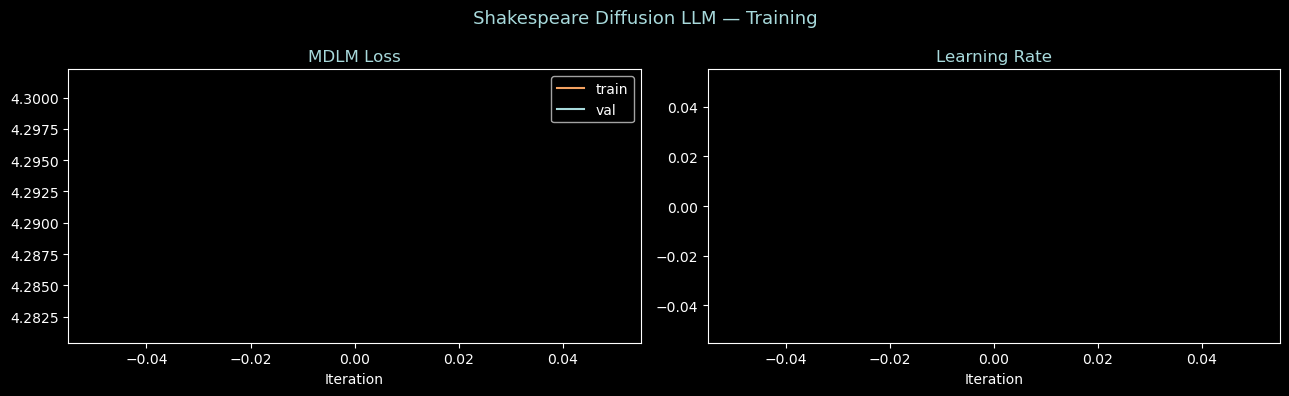

iter   250 | train 3.3124 | val 3.3056 | lr 1.50e-04 | 17s  💾 saved
iter   500 | train 3.3127 | val 3.3048 | lr 3.00e-04 | 19s  💾 saved
iter   750 | train 3.3081 | val 3.2994 | lr 2.99e-04 | 17s  💾 saved
iter  1000 | train 3.3164 | val 3.2990 | lr 2.97e-04 | 16s  💾 saved
iter  1250 | train 3.3111 | val 3.3020 | lr 2.93e-04 | 17s
iter  1500 | train 3.3109 | val 3.3004 | lr 2.88e-04 | 18s
iter  1750 | train 3.3114 | val 3.2992 | lr 2.82e-04 | 20s
iter  2000 | train 3.3173 | val 3.3013 | lr 2.74e-04 | 19s
iter  2250 | train 3.3135 | val 3.2999 | lr 2.65e-04 | 18s
iter  2500 | train 3.3074 | val 3.2963 | lr 2.55e-04 | 18s  💾 saved
iter  2750 | train 3.3120 | val 3.2989 | lr 2.44e-04 | 17s
iter  3000 | train 3.3164 | val 3.2982 | lr 2.32e-04 | 19s
iter  3250 | train 3.3074 | val 3.2996 | lr 2.20e-04 | 18s
iter  3500 | train 3.3120 | val 3.2995 | lr 2.07e-04 | 20s
iter  3750 | train 3.3101 | val 3.3000 | lr 1.93e-04 | 20s
iter  4000 | train 3.3072 | val 3.3001 | lr 1.79e-04 | 18s
iter  4250 

In [10]:
@torch.no_grad()
def estimate_loss(model, loader, noise_schedule, eval_iters, use_amp):
    model.eval()
    losses = []
    for i, x0 in enumerate(loader):
        if i >= eval_iters: break
        x0 = x0.to(device)
        loss = diffusion_loss(model, x0, noise_schedule, use_amp=False)  # always fp32 for eval
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses)) if losses else float('nan')


# ── History & plot setup ──────────────────────────────────────────────────────
history = {'iter': [], 'train_loss': [], 'val_loss': [], 'lr': []}
best_val = float('inf')

plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Shakespeare Diffusion LLM — Training', fontsize=13, color='#a8dadc')

def update_plot():
    iters = history['iter']
    for ax in axes: ax.cla()
    axes[0].plot(iters, history['train_loss'], label='train', color='#f4a261', lw=1.5)
    axes[0].plot(iters, history['val_loss'],   label='val',   color='#a8dadc', lw=1.5)
    axes[0].set_title('MDLM Loss', color='#a8dadc'); axes[0].legend()
    axes[0].set_xlabel('Iteration')
    axes[1].plot(iters, history['lr'], color='#90be6d', lw=1.5)
    axes[1].set_title('Learning Rate', color='#a8dadc')
    axes[1].set_xlabel('Iteration')
    fig.tight_layout(); plt.pause(0.001)


# ── Training ──────────────────────────────────────────────────────────────────
train_iter = iter(train_loader)
model.train()
t0 = time.time()
print(f'Starting training for {cfg.max_iters} iterations …\n')

for it in range(cfg.max_iters):

    # LR update
    lr = get_lr(it, cfg)
    for pg in optimizer.param_groups: pg['lr'] = lr

    # Eval
    if it % cfg.eval_interval == 0:
        tl = estimate_loss(model, train_loader, noise, cfg.eval_iters, cfg.use_amp)
        vl = estimate_loss(model, val_loader,   noise, cfg.eval_iters, cfg.use_amp)
        history['iter'].append(it)
        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['lr'].append(lr)

        tag = ''
        if vl < best_val:
            best_val = vl
            torch.save({'iter': it, 'model': model.state_dict(),
                        'optimizer': optimizer.state_dict(),
                        'val_loss': vl, 'cfg': cfg},
                       Path(cfg.out_dir) / 'best.pt')
            tag = '  💾 saved'

        elapsed = time.time() - t0
        print(f'iter {it:>5} | train {tl:.4f} | val {vl:.4f} | lr {lr:.2e} | {elapsed:.0f}s{tag}')
        update_plot()
        t0 = time.time()

    # Get batch
    try:
        x0 = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        x0 = next(train_iter)
    x0 = x0.to(device, non_blocking=True)

    # Forward + backward
    optimizer.zero_grad(set_to_none=True)
    loss = diffusion_loss(model, x0, noise, use_amp=cfg.use_amp)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
    scaler.step(optimizer)
    scaler.update()

print('\n✅ Training complete!')
plt.show()

## 11. Sampling — Iterative Denoising

Generation works in the **reverse** direction: start fully masked, denoise step by step.

At each step the model predicts the probability of every original token at every position.
We then **unmask** the most confident positions, and re-run the model on the sparser mask.

```
Step 0: [M][M][M][M][M][M][M][M][M][M]   ← 100% masked
Step 1: [M][M] T [M][M] o [M][M][M][M]   ← unmask 10% most confident
Step 2: [M] o  T  o [M] o  b [M][M] e    ← unmask next 10%
...                                        
Step N:  T  o     b  e     o  r     e     ← fully unmasked
```

Best val loss  : 3.2955
Random-chance  : 4.1897  (ln(vocab_size))
Improvement    : 0.8942 nats below chance



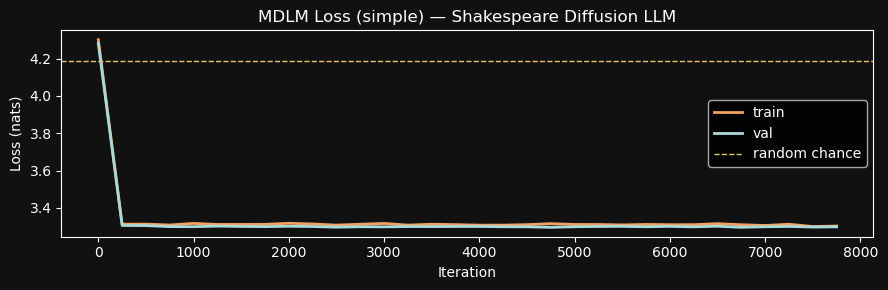

In [11]:
# ── Post-training diagnostics ─────────────────────────────────────────────────
# Loss at random chance for char-level: ln(66) ≈ 4.19  (lower = better)
# Simple MDLM loss is not directly comparable to GPT cross-entropy,
# but you should see a clear downward trend.
print(f'Best val loss  : {best_val:.4f}')
print(f'Random-chance  : {math.log(cfg.vocab_size):.4f}  (ln(vocab_size))')
print(f'Improvement    : {math.log(cfg.vocab_size) - best_val:.4f} nats below chance')
print()

# Plot final loss curve
plt.figure(figsize=(9, 3))
plt.plot(history['iter'], history['train_loss'], label='train', color='#f4a261', lw=2)
plt.plot(history['iter'], history['val_loss'],   label='val',   color='#a8dadc', lw=2)
plt.axhline(math.log(cfg.vocab_size), color='#e9c46a', ls='--', lw=1, label='random chance')
plt.title('MDLM Loss (simple) — Shakespeare Diffusion LLM', color='white')
plt.xlabel('Iteration'); plt.ylabel('Loss (nats)')
plt.legend(); plt.gca().set_facecolor('#111'); plt.gcf().set_facecolor('#111')
plt.tight_layout(); plt.savefig('diffusion_loss.png', dpi=150, bbox_inches='tight')
plt.show()


In [12]:
# Load best checkpoint
ckpt = torch.load(Path(cfg.out_dir) / 'best.pt', map_location=device)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'✅ Loaded best checkpoint | iter {ckpt["iter"]} | val loss {ckpt["val_loss"]:.4f}')

C:\Users\Rafael\AppData\Local\Temp\ipykernel_34492\3488303208.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(Path(cfg.out_dir) / 'best.pt', map_locati

✅ Loaded best checkpoint | iter 4750 | val loss 3.2955


In [13]:
@torch.no_grad()
def sample(
    model,
    noise_schedule,
    length      : int   = 128,
    sample_steps: int   = 20,
    temperature : float = 1.0,
    top_k       : int   = 40,
    prompt      : str   = '',       # optional left-fixed prefix
    verbose     : bool  = False,
):
    """
    Generate a sequence by iterative denoising.

    Strategy: Confidence-based unmasking (similar to MaskGIT / MDLM).
      At each reverse step we:
        1. Run the model on current xt + timestep.
        2. For each still-masked position, sample a candidate token.
        3. Keep the top-confidence fraction unmasked; re-mask the rest.
    """
    model.eval()
    T     = noise_schedule.T
    MASK  = noise_schedule.mask_id
    L     = length

    # Start fully masked
    xt = torch.full((1, L), MASK, dtype=torch.long, device=device)

    # Fix prompt tokens (they are never re-masked)
    prompt_ids  = encode(prompt) if prompt else []
    prompt_len  = min(len(prompt_ids), L)
    fixed_mask  = torch.zeros(L, dtype=torch.bool, device=device)  # True = fixed
    if prompt_len > 0:
        xt[0, :prompt_len]   = torch.tensor(prompt_ids[:prompt_len], device=device)
        fixed_mask[:prompt_len] = True

    # Reverse diffusion schedule: linearly spaced timesteps T → 1
    timesteps = torch.linspace(T, 1, sample_steps, dtype=torch.long, device=device)

    for step_idx, t_val in enumerate(timesteps):
        t_tensor  = t_val.unsqueeze(0)                  # (1,)
        logits    = model(xt, t_tensor)                 # (1, L, V)
        logits    = logits[0] / temperature             # (L, V)

        # Optional top-k filtering
        if top_k is not None:
            v, _  = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float('-inf')

        probs    = F.softmax(logits, dim=-1)            # (L, V)
        # Sample a candidate token at every position
        sampled  = torch.multinomial(probs, num_samples=1).squeeze(-1)  # (L,)
        # Confidence = probability of the sampled token
        conf     = probs[torch.arange(L), sampled]     # (L,)

        # Cosine unmasking schedule — slow start, faster finish
        # This prevents committing to wrong tokens too early
        frac_unmasked = 1.0 - math.cos(math.pi * (step_idx + 1) / (2 * sample_steps))
        n_total_free  = L - fixed_mask.sum().item()
        n_target      = max(1, int(frac_unmasked * n_total_free))
        already_unmasked = int((xt[0] != MASK).sum().item()) - int(fixed_mask.sum().item())
        n_unmask      = max(0, n_target - already_unmasked)

        # Only consider currently masked, non-fixed positions
        is_masked = (xt[0] == MASK) & ~fixed_mask
        if not is_masked.any():
            break

        # Pick top-confidence masked positions to reveal
        conf_masked               = conf.clone()
        conf_masked[~is_masked]   = -1.0
        _, top_idx = torch.topk(conf_masked, min(n_unmask, is_masked.sum().item()))
        xt[0, top_idx] = sampled[top_idx]

        if verbose:
            print(f'Step {step_idx+1:>2}/{sample_steps} | t={t_val.item():>3} | '
                  f'unmasked so far: {(xt[0] != MASK).sum().item()}/{L}')

    # Force any remaining masked tokens to most likely prediction
    still_masked = (xt[0] == MASK) & ~fixed_mask
    if still_masked.any():
        t_end   = torch.ones(1, dtype=torch.long, device=device)
        logits  = model(xt, t_end)[0]
        xt[0, still_masked] = logits[still_masked].argmax(-1)

    return decode(xt[0].tolist())

In [14]:
# ── Unconditional generation ──────────────────────────────────────────────────
print('=== Unconditional generation ===\n')
out = sample(model, noise, length=cfg.block_size,
             sample_steps=cfg.sample_steps, temperature=0.9, top_k=40)
print(out)
print()

=== Unconditional generation ===

                            a                         o  t                      o  e                   t      n              e  



In [15]:
# ── Prompted generation (prefix conditioning) ─────────────────────────────────
prompts = [
    'HAMLET:\n',
    'To be, or not to be',
    'Friends, Romans, countrymen',
]

for p in prompts:
    out = sample(model, noise, length=cfg.block_size,
                 sample_steps=cfg.sample_steps, temperature=0.9, top_k=40,
                 prompt=p)
    print(f'── Prompt: {p!r} {"─"*(48 - len(p))}')
    print(out)
    print()

── Prompt: 'HAMLET:\n' ────────────────────────────────────────
HAMLET:
                 e              o   a     e a e  e              e                                      ee   e  no       

── Prompt: 'To be, or not to be' ─────────────────────────────
To be, or not to be         t                         s            e     t                                     n t  e           

── Prompt: 'Friends, Romans, countrymen' ─────────────────────
Friends, Romans, countrymen    e                      e    e             e                                               o    a 



In [16]:
# ── Verbose step-by-step denoising (shows the process) ───────────────────────
print('=== Verbose denoising trace ===\n')
out = sample(model, noise, length=64,
             sample_steps=10, temperature=1.0, top_k=50, verbose=True)
print('\nFinal output:')
print(out)

=== Verbose denoising trace ===

Step  1/10 | t=100 | unmasked so far: 1/64
Step  2/10 | t= 89 | unmasked so far: 3/64
Step  3/10 | t= 78 | unmasked so far: 6/64
Step  4/10 | t= 67 | unmasked so far: 12/64
Step  5/10 | t= 56 | unmasked so far: 18/64
Step  6/10 | t= 45 | unmasked so far: 26/64
Step  7/10 | t= 34 | unmasked so far: 34/64
Step  8/10 | t= 23 | unmasked so far: 44/64
Step  9/10 | t= 12 | unmasked so far: 53/64
Step 10/10 | t=  1 | unmasked so far: 63/64

Final output:
  o     s  la   o  tr  f  o ri e  ee    h  h  M    r ,  r  a    


## 12. Unique Capability: Infilling

Unlike autoregressive GPT, a diffusion model can natively **infill** — fill in the middle
of a known text. Fix both a prefix *and* a suffix, let the model fill the gap.

In [17]:
@torch.no_grad()
def infill(
    model,
    noise_schedule,
    prefix      : str,
    suffix      : str,
    total_length: int   = 128,
    sample_steps: int   = 20,
    temperature : float = 1.0,
    top_k       : int   = 40,
):
    """
    Fill in the middle between prefix and suffix.
    Prefix is fixed at the start, suffix is fixed at the end,
    everything in between is generated by the diffusion model.
    """
    MASK = noise_schedule.mask_id
    L    = total_length

    prefix_ids = encode(prefix)
    suffix_ids = encode(suffix)
    pl, sl     = len(prefix_ids), len(suffix_ids)

    assert pl + sl < L, f'Prefix+suffix ({pl+sl}) must be shorter than total_length ({L})'

    # Build initial sequence: prefix + [MASK]s + suffix
    xt = torch.full((1, L), MASK, dtype=torch.long, device=device)
    xt[0, :pl]          = torch.tensor(prefix_ids, device=device)
    xt[0, L - sl:]      = torch.tensor(suffix_ids, device=device)

    fixed = torch.zeros(L, dtype=torch.bool, device=device)
    fixed[:pl]     = True
    fixed[L - sl:] = True

    timesteps = torch.linspace(noise_schedule.T, 1, sample_steps,
                               dtype=torch.long, device=device)
    for step_idx, t_val in enumerate(timesteps):
        logits   = model(xt, t_val.unsqueeze(0))[0] / temperature
        if top_k:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float('-inf')
        probs   = F.softmax(logits, dim=-1)
        sampled = torch.multinomial(probs, 1).squeeze(-1)
        conf    = probs[torch.arange(L), sampled]

        frac         = 1.0 - math.cos(math.pi * (step_idx + 1) / (2 * sample_steps))
        n_total_free = L - fixed.sum().item()
        n_target     = max(1, int(frac * n_total_free))
        already_done = int((xt[0] != MASK).sum().item()) - int(fixed.sum().item())
        n_unmask     = max(0, n_target - already_done)
        is_masked    = (xt[0] == MASK) & ~fixed
        if not is_masked.any(): break

        conf_m              = conf.clone()
        conf_m[~is_masked]  = -1.0
        _, top_idx = torch.topk(conf_m, min(n_unmask, is_masked.sum().item()))
        xt[0, top_idx] = sampled[top_idx]

    still = (xt[0] == MASK) & ~fixed
    if still.any():
        logits = model(xt, torch.ones(1, dtype=torch.long, device=device))[0]
        xt[0, still] = logits[still].argmax(-1)

    return decode(xt[0].tolist())


# ── Demo infilling ────────────────────────────────────────────────────────────
examples = [
    ('HAMLET:\nTo be, or not to be', 'the question.'),
    ('ROMEO:\nBut, soft! what light through', 'breaks?'),
    ('All the world\'s a stage,', 'merely players.'),
]

for prefix, suffix in examples:
    result = infill(model, noise,
                    prefix=prefix, suffix=suffix,
                    total_length=cfg.block_size,
                    sample_steps=cfg.sample_steps)
    print(f'PREFIX : {prefix!r}')
    print(f'SUFFIX : {suffix!r}')
    print(f'RESULT :\n{result}')
    print('─' * 60)

PREFIX : 'HAMLET:\nTo be, or not to be'
SUFFIX : 'the question.'
RESULT :
HAMLET:
To be, or not to be                                             e                e e            t       o  the question.
────────────────────────────────────────────────────────────
PREFIX : 'ROMEO:\nBut, soft! what light through'
SUFFIX : 'breaks?'
RESULT :
ROMEO:
But, soft! what light through         t       s   a               o                                         t     breaks?
────────────────────────────────────────────────────────────
PREFIX : "All the world's a stage,"
SUFFIX : 'merely players.'
RESULT :
All the world's a stage,    ,    r                   t    a                   e e   a                           rmerely players.
────────────────────────────────────────────────────────────


## 13. Comparison: GPT vs Diffusion

Run this cell after training both notebooks to compare the two architectures side by side.

In [18]:
print('GPT vs Diffusion LLM — Architecture Comparison')
print('=' * 60)
rows = [
    ('Parameters',        '~10.75 M',    f'{model.num_params()/1e6:.2f} M'),
    ('Attention type',    'Causal',       'Bidirectional'),
    ('Timestep input',    'None',         'Sinusoidal + MLP'),
    ('Generation',        'L sequential steps', f'{cfg.sample_steps} parallel passes'),
    ('Infilling',         '❌ Hard',      '✅ Native'),
    ('Training target',   'Next token',   'Masked tokens (MDLM)'),
    ('Loss weighting',    'Uniform',      'ELBO reweighted by 1/β(t)'),
    ('Context',           'Left only',    'Left + Right'),
]
print(f'{"Property":<22} {"GPT":<26} {"Diffusion":<26}')
print('-' * 74)
for r in rows:
    print(f'{r[0]:<22} {r[1]:<26} {r[2]:<26}')

GPT vs Diffusion LLM — Architecture Comparison
Property               GPT                        Diffusion                 
--------------------------------------------------------------------------
Parameters             ~10.75 M                   11.29 M                   
Attention type         Causal                     Bidirectional             
Timestep input         None                       Sinusoidal + MLP          
Generation             L sequential steps         50 parallel passes        
Infilling              ❌ Hard                     ✅ Native                  
Training target        Next token                 Masked tokens (MDLM)      
Loss weighting         Uniform                    ELBO reweighted by 1/β(t) 
Context                Left only                  Left + Right              


## 14. Further Reading & Next Steps

| Topic | Resource |
|-------|----------|
| **MDLM paper** (this notebook's basis) | Sahoo et al. 2024 — `arxiv.org/abs/2406.07524` |
| **Diffusion-LM** (continuous embedding diffusion) | Li et al. 2022 — `arxiv.org/abs/2205.14217` |
| **Mercury** (production discrete diffusion LLM) | Inception Labs 2025 — `arxiv.org/abs/2501.00757` |
| **MaskGIT** (confidence-based unmasking — used in sampler above) | Chang et al. 2022 — `arxiv.org/abs/2202.04200` |
| **Scale this up** | Increase `n_layer=12, n_head=12, n_embd=768` (~85M params) |
| **Better schedule** | Try cosine or sigmoid noise schedules instead of linear |
| **BPE tokenizer** | Swap in `tiktoken` — same change as the GPT notebook |
| **Classifier-Free Guidance** | Condition generation on a style/genre label |